# Week 2 - Tuesday: Decision Trees and k-Nearest Neighbors

**Datasets:** Wine and Breast Cancer (built into scikit-learn, no internet needed)

**Goal:** understand how a Decision Tree and kNN make predictions, and see overfitting and the effect of scaling.

**Done when:** I can explain what happens if k = 1 and what happens if `max_depth` is huge.

---
### Quick theory
**Decision Tree**
- Splits the data with yes/no questions on features (e.g. "is color_intensity <= 3.82?").
- **Gini impurity** (or entropy) measures how mixed the classes are in a node; 0 means pure. The tree picks the split that makes the groups purest.
- A very deep tree keeps splitting until each leaf is pure, so it memorises the training data (overfitting).
- Controls: `max_depth`, `min_samples_leaf`. Trees do **not** need feature scaling.

**k-Nearest Neighbors (kNN)**
- To predict a point, find its **k closest** training points and take a **majority vote**.
- Uses distance, so features with big numbers dominate. **Scaling matters a lot.**
- Small k overfits, large k underfits.

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

## Load the data and split it
One stratified train/test split per dataset (25% test).

In [2]:
datasets = {
    "Wine": load_wine(as_frame=True),
    "Breast Cancer": load_breast_cancer(as_frame=True),
}

splits = {}
for name, data in datasets.items():
    X, y = data.data, data.target
    splits[name] = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
    print(f"{name}: {X.shape[0]} rows, {X.shape[1]} features, classes = {[str(c) for c in data.target_names]}")

# A look at the Wine features: very different scales (important for kNN later)
datasets["Wine"].data.describe().loc[["min", "max"]].T.round(2)

Wine: 178 rows, 13 features, classes = ['class_0', 'class_1', 'class_2']
Breast Cancer: 569 rows, 30 features, classes = ['malignant', 'benign']


,min,max
alcohol,11.03,14.83
malic_acid,0.74,5.80
ash,1.36,3.23
alcalinity_of_ash,10.60,30.00
magnesium,70.00,162.00
total_phenols,0.98,3.88
flavanoids,0.34,5.08
nonflavanoid_phenols,0.13,0.66
proanthocyanins,0.41,3.58
color_intensity,1.28,13.00


## Step 1: Train a Decision Tree, plot it, read the first split
First a full-depth tree to see its accuracy and the **first split** (the root question), then a small tree (`max_depth=3`) so the plot is readable.

In [3]:
for name, data in datasets.items():
    X_train, X_test, y_train, y_test = splits[name]
    tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

    feature = X_train.columns[tree.tree_.feature[0]]
    threshold = tree.tree_.threshold[0]
    print(f"{name}: train acc = {tree.score(X_train, y_train):.3f}, test acc = {tree.score(X_test, y_test):.3f}")
    print(f"   First split: is '{feature}' <= {threshold:.3f} ?\n")

Wine: train acc = 1.000, test acc = 0.956
   First split: is 'color_intensity' <= 3.820 ?

Breast Cancer: train acc = 1.000, test acc = 0.923
   First split: is 'worst radius' <= 16.795 ?



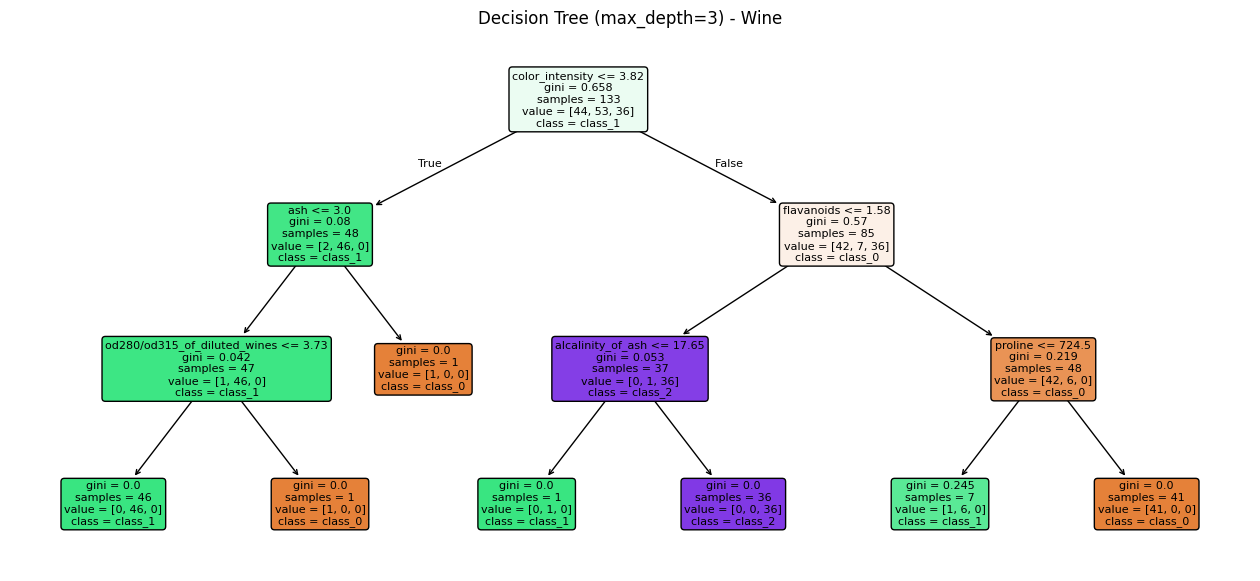

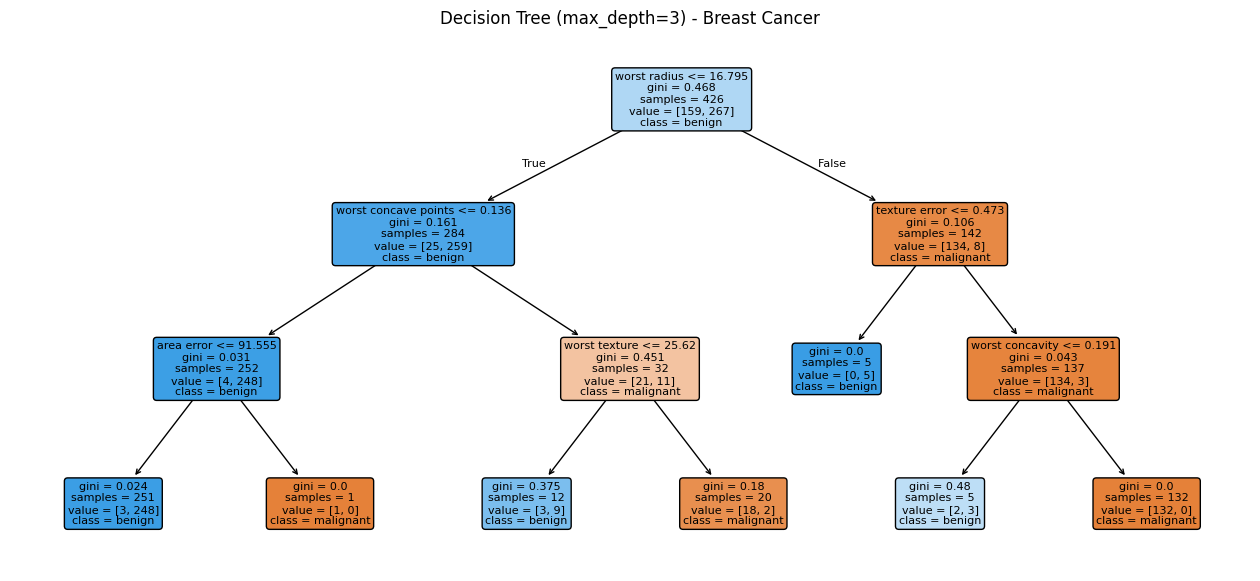

In [4]:
for name, data in datasets.items():
    X_train, X_test, y_train, y_test = splits[name]
    small_tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)

    plt.figure(figsize=(16, 7))
    plot_tree(small_tree, feature_names=list(X_train.columns),
              class_names=[str(c) for c in data.target_names],
              filled=True, rounded=True, fontsize=8)
    plt.title(f"Decision Tree (max_depth=3) - {name}")
    plt.show()

**How to read the tree:** the top box is the first question. Each box shows the question, its `gini` impurity, the number of `samples`, the class counts in `value`, and the majority `class`. The colour shows the class, and darker means purer.

## Step 2: Vary `max_depth` (1 to 15) and plot train vs test accuracy

Wine: best test acc 0.956 at max_depth=3; train acc at depth 15 = 1.000
Breast Cancer: best test acc 0.944 at max_depth=3; train acc at depth 15 = 1.000


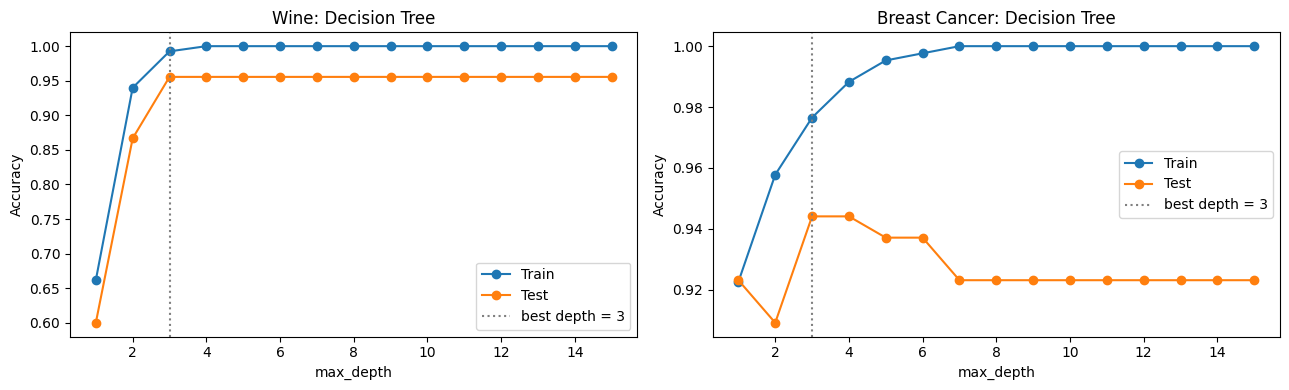

In [5]:
depths = range(1, 16)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, name in zip(axes, datasets):
    X_train, X_test, y_train, y_test = splits[name]
    train_acc, test_acc = [], []
    for d in depths:
        t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
        train_acc.append(t.score(X_train, y_train))
        test_acc.append(t.score(X_test, y_test))

    best_depth = depths[test_acc.index(max(test_acc))]
    print(f"{name}: best test acc {max(test_acc):.3f} at max_depth={best_depth}; "
          f"train acc at depth 15 = {train_acc[-1]:.3f}")

    ax.plot(depths, train_acc, marker="o", label="Train")
    ax.plot(depths, test_acc, marker="o", label="Test")
    ax.axvline(best_depth, color="grey", linestyle=":", label=f"best depth = {best_depth}")
    ax.set_title(f"{name}: Decision Tree")
    ax.set_xlabel("max_depth")
    ax.set_ylabel("Accuracy")
    ax.legend()

plt.tight_layout()
plt.show()

**Reading the graph:** the train accuracy climbs to 1.0 as the tree gets deeper, but the test accuracy stops improving (or drops). A big gap between train and test is the sign of **overfitting**.

## Step 3: kNN with and without scaling (Wine)
Wine features have very different scales (e.g. `proline` is in the hundreds, others are below 1), so without scaling the large feature dominates the distance.

Without scaling: test acc = 0.778
With scaling   : test acc = 0.933


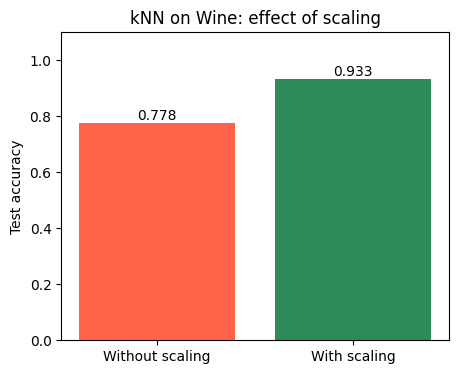

In [6]:
X_train, X_test, y_train, y_test = splits["Wine"]

knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)

# The scaler is inside a pipeline, so it is fitted on training data only
knn_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_scaled.fit(X_train, y_train)

raw_acc = knn_raw.score(X_test, y_test)
scaled_acc = knn_scaled.score(X_test, y_test)
print(f"Without scaling: test acc = {raw_acc:.3f}")
print(f"With scaling   : test acc = {scaled_acc:.3f}")

plt.figure(figsize=(5, 4))
bars = plt.bar(["Without scaling", "With scaling"], [raw_acc, scaled_acc], color=["tomato", "seagreen"])
plt.bar_label(bars, fmt="%.3f")
plt.ylim(0, 1.1)
plt.ylabel("Test accuracy")
plt.title("kNN on Wine: effect of scaling")
plt.show()

## Step 4: Vary k (1 to 30) and plot accuracy against k
Scaling is used here, since kNN needs it.

Wine: k=1 -> train acc 1.000, test acc 0.956; best test acc 1.000 at k=15


Breast Cancer: k=1 -> train acc 1.000, test acc 0.951; best test acc 0.979 at k=5


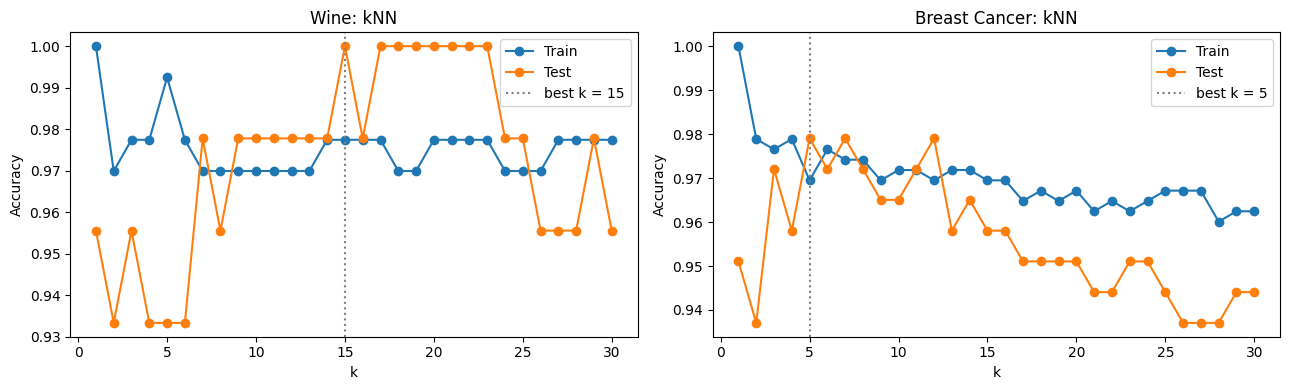

In [7]:
ks = range(1, 31)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, name in zip(axes, datasets):
    X_train, X_test, y_train, y_test = splits[name]
    train_acc, test_acc = [], []
    for k in ks:
        m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
        m.fit(X_train, y_train)
        train_acc.append(m.score(X_train, y_train))
        test_acc.append(m.score(X_test, y_test))

    best_k = ks[test_acc.index(max(test_acc))]
    print(f"{name}: k=1 -> train acc {train_acc[0]:.3f}, test acc {test_acc[0]:.3f}; "
          f"best test acc {max(test_acc):.3f} at k={best_k}")

    ax.plot(ks, train_acc, marker="o", label="Train")
    ax.plot(ks, test_acc, marker="o", label="Test")
    ax.axvline(best_k, color="grey", linestyle=":", label=f"best k = {best_k}")
    ax.set_title(f"{name}: kNN")
    ax.set_xlabel("k")
    ax.set_ylabel("Accuracy")
    ax.legend()

plt.tight_layout()
plt.show()

**Reading the graph:** at k = 1 the train accuracy is 1.0 (each point is its own nearest neighbour), but the test accuracy is lower, which is overfitting. As k grows the curves come closer, and a very large k averages over too many points and underfits.

---
## Done-when answers
- **What happens if k = 1?** The model copies the label of its single nearest neighbour. Train accuracy is 1.0 and it follows noise, so it overfits.
- **What happens if `max_depth` is huge?** The tree keeps splitting until every leaf is pure, so it memorises the training data (train accuracy 1.0) and test accuracy stops improving or drops.

## Notes (Tuesday)
- **How a tree decides a split:** it tries questions on features and picks the one that makes the resulting groups purest (lowest Gini impurity).
- **How kNN predicts:** finds the k nearest training points and takes a majority vote.
- **Why kNN needs scaling and trees don't:** kNN uses distances, so a feature with big numbers dominates. A tree asks one feature at a time ("is x <= t?"), so the scale does not matter.
- **Overfitting signs:** tree - very deep, train accuracy far above test. kNN - very small k, train accuracy far above test.

## My results
| Experiment | Result |
|---|---|
| Wine tree, first split | `color_intensity <= 3.82` |
| Breast Cancer tree, first split | `worst radius <= 16.795` |
| Tree best depth | max_depth = 3 on both datasets (train accuracy reaches 1.0 at depth 15) |
| kNN on Wine, no scaling vs scaling | 0.778 vs 0.933 |
| Best k | about 15 on Wine, 5 on Breast Cancer |